# EDA

## IMPORTAR PAQUETES

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import janitor
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


## CARGAR DATOS

In [3]:
cat = pd.read_pickle('../02_datos/03_Entrenamiento/cat_calidad.pkl')
num = pd.read_pickle('../02_datos/03_Entrenamiento/num_calidad.pkl')

## EDA CATEGÓRICAS

### Variables a analizar

In [4]:
variables = ['antigüedad_empleo', 'ingresos_verificados', 'rating', 'vivienda', 'finalidad', 'num_cuotas', 'estado']

### Frecuencias

Función que calcula la frecuencia relativa de cada valor por variable

In [5]:
def frecuencias_cat(df_cat):

    resultado = df_cat[variables].apply(lambda x: x.value_counts(normalize = True)).T.stack().dropna() \
                        .to_frame().reset_index() \
                        .rename(columns={'level_0': 'Variable', 'level_1': 'Valor', 0: 'Frecuencia'}) \
                        .sort_values(by=['Variable', 'Frecuencia'])
    return (resultado)

In [6]:
frecuencias_cat(cat)

,Variable,Valor,Frecuencia
9,antigüedad_empleo,9 years,0.035
8,antigüedad_empleo,8 years,0.041
7,antigüedad_empleo,7 years,0.041
6,antigüedad_empleo,6 years,0.046
4,antigüedad_empleo,4 years,0.061
5,antigüedad_empleo,5 years,0.063
11,antigüedad_empleo,desconocido,0.065
0,antigüedad_empleo,1 year,0.065
3,antigüedad_empleo,3 years,0.081
10,antigüedad_empleo,< 1 year,0.085


### Gráficos

Función que genera un gráfico de barras horizontales por cada variable categórica

In [7]:
def graficos_eda_categoricas(cat):

    #Calculamos el número de filas de necesitamos
    from math import ceil
    filas = ceil(cat.shape[1] / 2)

    #Definimos el gráfico
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(16, filas * 6))

    #Aplanamos para iterar el gráfico como si fuera de 1 dimension en lugar de 2
    ax = ax.flat

    #Creamos el bucle que va añadiendo el gráfico
    for cada, variable in enumerate(cat):
        cat[variable].value_counts().plot.barh(ax = ax[cada])
        ax[cada].set_title(variable, fontsize = 12, fontweight = 'bold')
        ax[cada].tick_params(labelsize = 12)

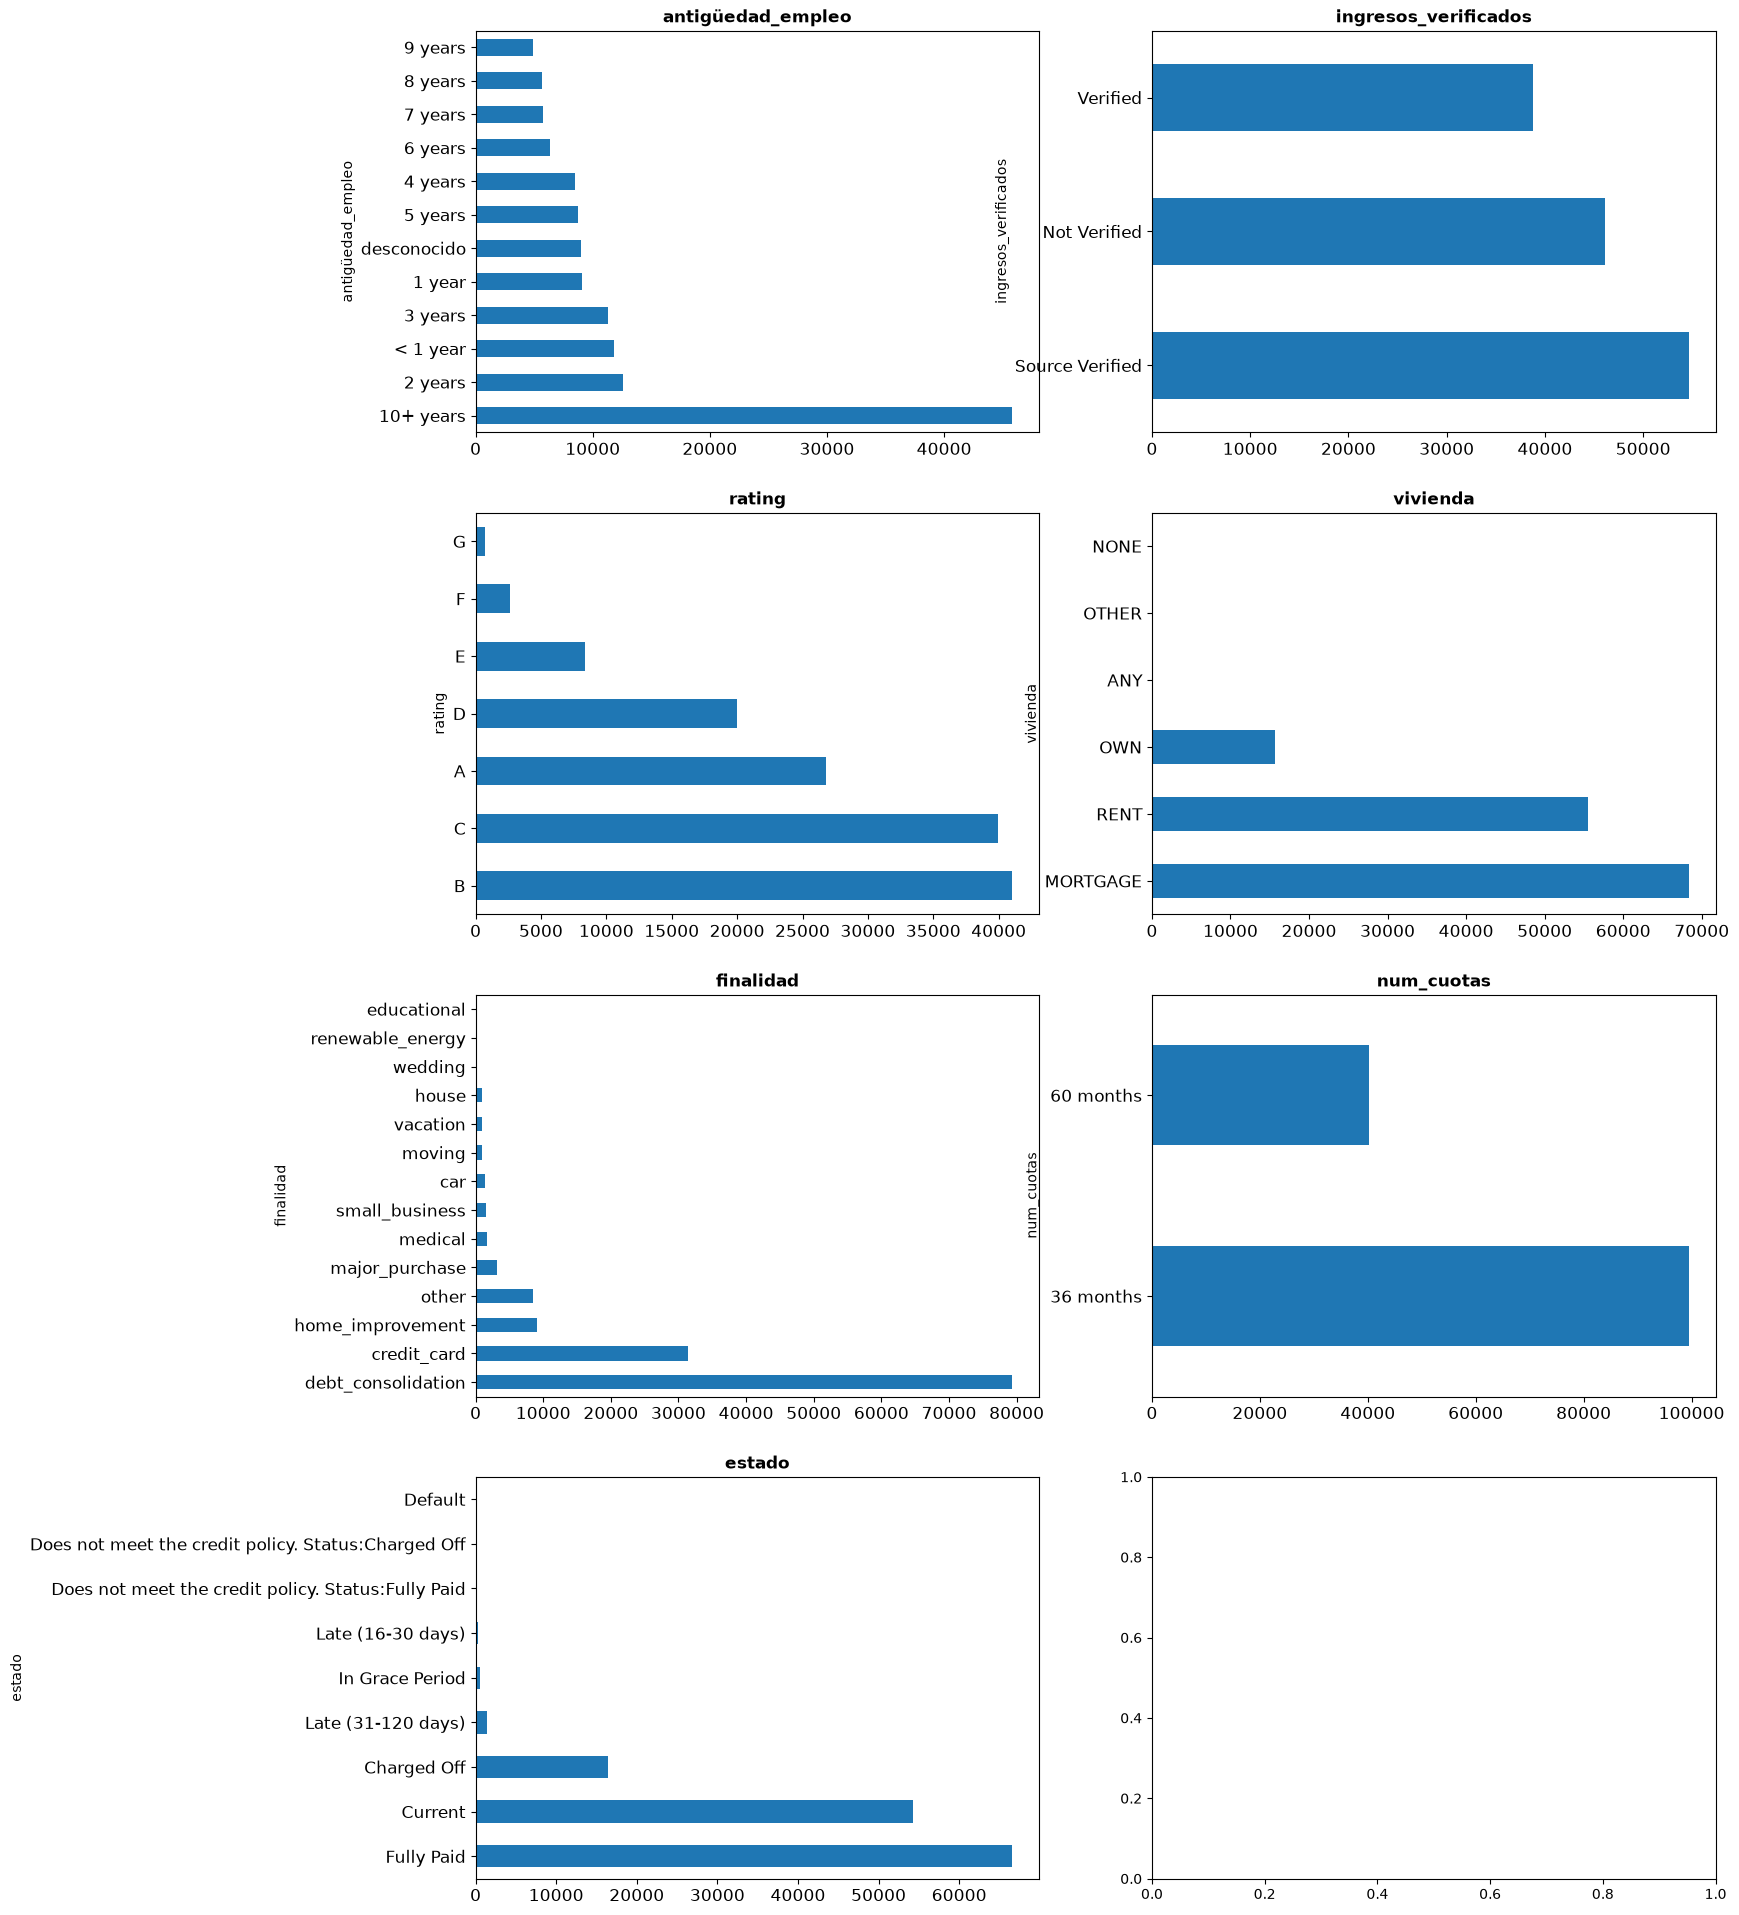

In [8]:
graficos_eda_categoricas(cat[variables])

Conclusiones: 

En transformación:
 - En vivienda juntar ANY, NONE y OTHER a la categoría mayoritaría
 - En finalidad juntar renewable_energy, educational y wedding en 'otros'
 - Crear la target apartir de estado

## EDA NUMÉRICAS

#### Análisis estadístico

In [9]:
def estadisticos_cont(num):
    #Calculamos el describe
    estadisticos = num.describe().T
    #Añadimos la mediana
    estadisticos['median'] = num.median()
    #Reordemaos para que la mediana este al lado de la media
    estadisticos = estadisticos.iloc[:, [0,1,8,2,3,4,5,6,7]]

    #Lo devolvemos
    return (estadisticos)

In [10]:
estadisticos_cont(num)

,count,mean,median,std,min,25%,50%,75%,max
id_cliente,139604.000,80320397.856,84424456.500,44948019.817,65640.000,44895700.250,84424456.500,122364872.000,145637284.000
ingresos,139604.000,76236.603,65000.000,45742.164,0.000,46000.000,65000.000,93000.000,400000.000
dti,139604.000,18.821,17.800,14.335,-1.000,11.950,17.800,24.440,999.000
num_hipotecas,139604.000,1.514,1.000,1.883,0.000,0.000,1.000,2.000,32.000
num_lineas_credito,139604.000,11.618,11.000,5.645,0.000,8.000,11.000,14.000,84.000
porc_tarjetas_75p,139604.000,41.063,33.300,36.439,0.000,0.000,33.300,66.700,100.000
porc_uso_revolving,139604.000,50.308,50.300,24.722,0.000,31.500,50.300,69.400,184.600
num_cancelaciones_12meses,139604.000,0.009,0.000,0.104,0.000,0.000,0.000,0.000,7.000
num_derogatorios,139604.000,0.198,0.000,0.556,0.000,0.000,0.000,0.000,24.000
num_meses_desde_ult_retraso,139604.000,16.805,0.000,23.018,0.000,0.000,0.000,31.000,195.000


#### Análisis Gráfico

In [11]:
def graficos_eda_continuas(num):

    #Calculamos el número de filas de necesitamos
    from math import ceil
    filas = ceil(num.shape[1] / 2)

    #Definimos el gráfico
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(16, filas * 6))

    #Aplanamos para iterar el gráfico como si fuera de 1 dimension en lugar de 2
    ax = ax.flat

    #Creamos el bucle que va añadiendo el gráfico
    for cada, variable in enumerate(num):
        num[variable].plot.density(ax = ax[cada])
        ax[cada].set_title(variable, fontsize = 12, fontweight = 'bold')
        ax[cada].tick_params(labelsize = 12)

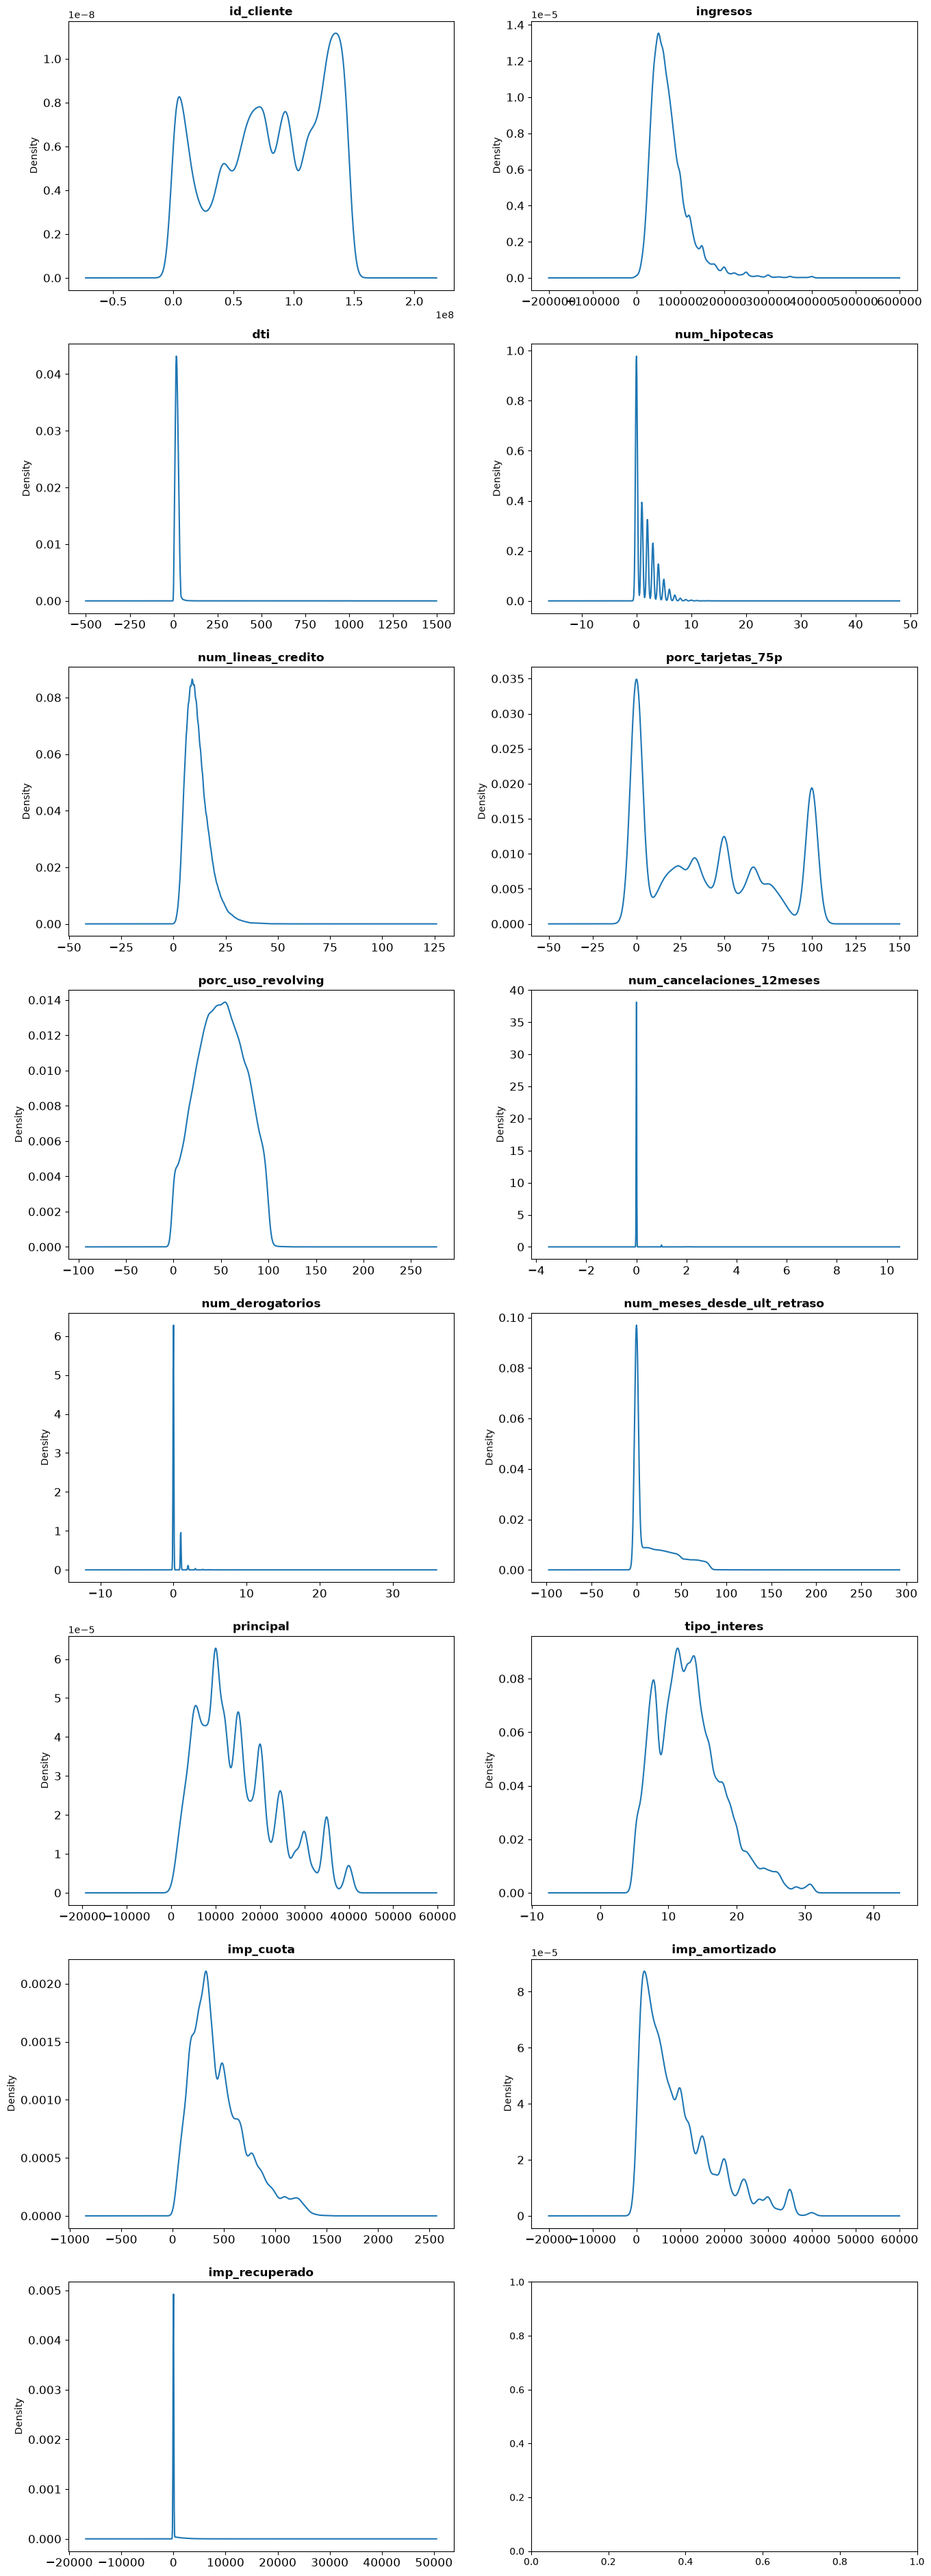

In [12]:
graficos_eda_continuas(num)

In [13]:
ratios = num[['principal', 'imp_amortizado', 'imp_recuperado']].copy()

In [14]:
ratios['r_amortizado_principal'] = ratios.imp_amortizado / ratios.principal
ratios['r_recuperado_principal'] = ratios.imp_recuperado / ratios.principal 

In [16]:
ratios.describe().T

,count,mean,std,min,25%,50%,75%,max
principal,139604.000,15055.312,9178.448,500.000,8000.000,12800.000,20000.000,40000.000
imp_amortizado,139604.000,9520.757,8307.124,0.000,3021.055,7000.000,13941.880,40000.000
imp_recuperado,139604.000,146.602,779.809,0.000,0.000,0.000,0.000,33666.340
r_amortizado_principal,139604.000,0.663,0.370,0.000,0.274,0.874,1.000,1.000
r_recuperado_principal,139604.000,0.009,0.042,0.000,0.000,0.000,0.000,1.221
